# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

brut = pd.read_csv("donnees/consommation_brut.csv")

print(brut.shape)
print(brut.dtypes)
print(brut.isna().sum())
print("Lignes en double :", brut.duplicated().sum())

(300, 4)
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Écritures différentes :", brut["quartier"].nunique())

Écritures différentes : 43


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")

non_convertibles = brut.loc[
    converti.isna() & brut["kwh"].notna(),
    "kwh"
]

print(non_convertibles.unique())

<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()

propre["kwh"] = (
    propre["kwh"]
    .str.replace("kWh", "", case=False, regex=False)
    .str.replace(r"\s+", "", regex=True)
)

propre["kwh"] = pd.to_numeric(propre["kwh"])

print("Manquants :", propre["kwh"].isna().sum())

Manquants : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")

def forme(nom):
    return " ".join(str(nom).lower().split())

officiel = {forme(q): q for q in quartiers["quartier"]}

nouveau = propre["quartier"].map(
    lambda q: officiel.get(forme(q))
)

print("Noms perdus :", nouveau.isna().sum())
print(propre.loc[nouveau.isna(), "quartier"].unique())

propre["quartier"] = nouveau

print("Quartiers :", propre["quartier"].nunique())


Noms perdus : 0
<ArrowStringArray>
[]
Length: 0, dtype: str
Quartiers : 12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"]).reset_index(drop=True)

print(propre.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")

trop_grand = propre["kwh"] > 3 * mediane

print(
    propre.loc[
        trop_grand,
        ["mois", "quartier", "kwh"]
    ]
)

propre.loc[trop_grand, "kwh"] = (
    propre.loc[trop_grand, "kwh"] / 10
)

print("Maximum :", propre["kwh"].max())


        mois        quartier        kwh
82   2025-02       Delmas 33  3602600.0
127  2025-02       Delmas 75  2012700.0
187  2024-02  Morne Calvaire  1439200.0
232  2024-01          Rue 15   997700.0
Maximum : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv("donnees/consommation.csv")

propre["kwh"] = propre["kwh"].astype(int)

cle = ["mois", "quartier"]

a = (
    propre
    .sort_values(cle)
    .reset_index(drop=True)
)

b = (
    reference
    .merge(propre[cle], on=cle)[list(propre.columns)]
    .sort_values(cle)
    .reset_index(drop=True)
)

print(a.equals(b))

True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
avant = len(propre)

avec_quartiers = propre.merge(
    quartiers,
    on="quartier",
    how="left",
    validate="m:1"
)

avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)

avec_quartiers["annee"] = (
    avec_quartiers["mois"]
    .str[:4]
    .astype(int)
)

print(avant, "->", len(avec_quartiers))

masque = (
    (avec_quartiers["quartier"] == "Bas-Peu-de-Chose")
    &
    (avec_quartiers["mois"] == "2024-01")
)

print(
    avec_quartiers.loc[
        masque,
        "kwh_par_abonne"
    ]
)

279 -> 279
0    85.8
Name: kwh_par_abonne, dtype: float64


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")

avant = len(avec_quartiers)

avec_meteo = avec_quartiers.merge(
    meteo,
    on=["mois", "commune"],
    how="left",
    validate="m:1"
)

print(avant, "->", len(avec_meteo))

print(
    "Températures manquantes :",
    avec_meteo["temperature_c"].isna().sum()
)

279 -> 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv(
    "donnees/consommation_propre.csv",
    index=False
)

relu = pd.read_csv(
    "donnees/consommation_propre.csv"
)

print(relu.shape)

(279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


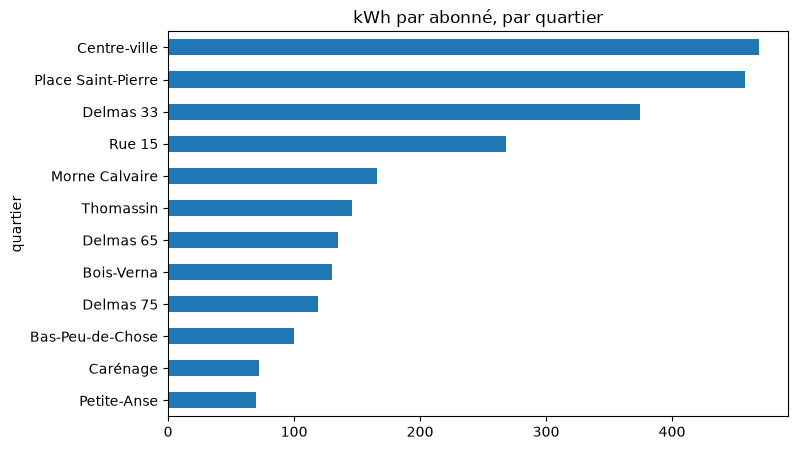

In [12]:
par_type = (
    relu.groupby("type")["kwh_par_abonne"]
    .mean()
    .round(1)
)

print(par_type)

classement = (
    relu.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)

print(classement)

classement.sort_values().plot.barh(
    figsize=(8, 5),
    title="kWh par abonné, par quartier"
)

plt.show()

**Ce qu'on en conclut :**

Les quartiers commerciaux consomment beaucoup plus d'électricité par abonné que les quartiers résidentiels. Centre-ville et Place Saint-Pierre occupent les premières places du classement, suivis par Delmas 33.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_pct
commune                                 
Cap-Haïtien      4.59   5.62        22.5
Pétion-Ville     8.60   9.68        12.6
Port-au-Prince  10.09  10.31         2.3
Delmas          11.61  11.74         1.1


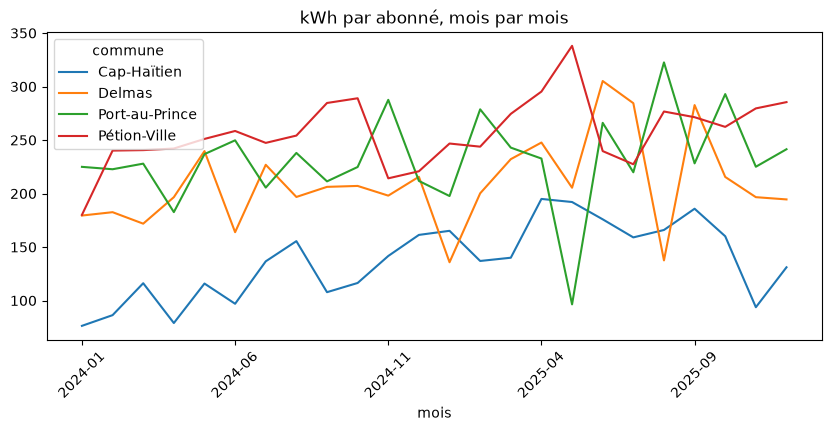

In [13]:
croise = relu.pivot_table(
    index="commune",
    columns="annee",
    values="kwh",
    aggfunc="sum"
)

croise["hausse_pct"] = (
    (croise[2025] / croise[2024] - 1)
    * 100
)

croise = croise.sort_values(
    "hausse_pct",
    ascending=False
)

resume = croise.copy()

resume[[2024, 2025]] = (
    resume[[2024, 2025]] / 1e6
).round(2)

resume["hausse_pct"] = (
    resume["hausse_pct"]
    .round(1)
)

print(resume)

courbes = relu.pivot_table(
    index="mois",
    columns="commune",
    values="kwh_par_abonne",
    aggfunc="mean"
)

courbes.plot(
    figsize=(10, 4),
    title="kWh par abonné, mois par mois"
)

plt.xticks(rotation=45)

plt.show()

**Ce qu'on en conclut :**

Entre 2024 et 2025, Cap-Haïtien enregistre la plus forte progression, passant de 4.59 à 5.62 millions de kWh, soit une hausse d'environ 22.5 %. À l'inverse, Delmas présente l'augmentation la plus faible avec seulement 1.1 %.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

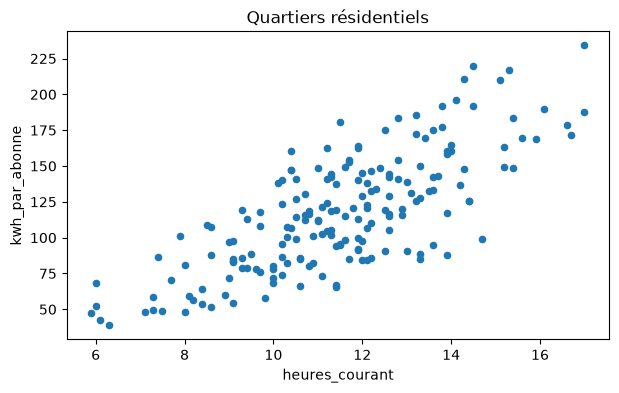

Avec heures_courant : 0.76
Avec temperature_c  : -0.15


In [14]:
residentiel = relu[
    relu["type"] == "Résidentiel"
]

residentiel.plot.scatter(
    x="heures_courant",
    y="kwh_par_abonne",
    figsize=(7, 4),
    title="Quartiers résidentiels"
)

plt.show()

print(
    "Avec heures_courant :",
    round(
        residentiel["kwh_par_abonne"].corr(
            residentiel["heures_courant"]
        ),
        2
    )
)

print(
    "Avec temperature_c  :",
    round(
        residentiel["kwh_par_abonne"].corr(
            residentiel["temperature_c"]
        ),
        2
    )
)


**Ce qu'on en conclut :**

Dans les quartiers résidentiels, la consommation moyenne par abonné est davantage associée aux heures de courant disponibles (corrélation de 0.76) qu'à la température, dont la corrélation est faible et négative (-0.15).

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                  Q1  médiane    Q3
commune                            
Cap-Haïtien      8.3     10.0  11.7
Delmas          10.1     11.9  13.0
Port-au-Prince  10.7     11.6  13.1
Pétion-Ville    10.4     11.6  13.0


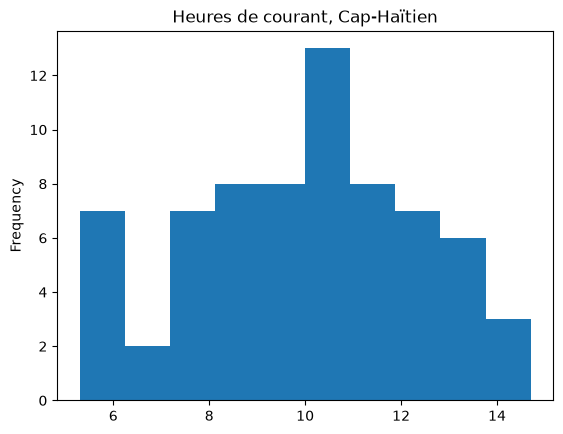

3 relevés
        mois   quartier  heures_courant
81   2025-01  Delmas 33             7.4
227  2025-08   Carénage             7.3
253  2025-11     Rue 15             5.9


In [15]:
stats = (
    relu.groupby("commune")["heures_courant"]
    .describe()[["25%", "50%", "75%"]]
)

stats.columns = [
    "Q1",
    "médiane",
    "Q3"
]

print(stats.round(1))

relu[
    relu["commune"] == "Cap-Haïtien"
]["heures_courant"].plot.hist(
    bins=10,
    title="Heures de courant, Cap-Haïtien"
)

plt.show()

courts = relu[
    (relu["annee"] == 2025)
    &
    (relu["heures_courant"] < 8)
]

print(len(courts), "relevés")

print(
    courts[
        ["mois", "quartier", "heures_courant"]
    ]
)

**Ce qu'on en conclut :**

Cap-Haïtien est la commune où les coupures semblent les plus importantes, avec une médiane de 10 heures de courant par jour. En 2025, seuls trois relevés sont inférieurs à huit heures de courant : Carénage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
print(
    relu.nlargest(
        3,
        "kwh"
    )[[
        "mois",
        "quartier",
        "type",
        "kwh"
    ]]
)

       mois      quartier        type     kwh
87  2025-07     Delmas 33  Commercial  742780
56  2024-11  Centre-ville  Commercial  597730
88  2025-09     Delmas 33  Commercial  591420


**Ce qu'on en conclut :**

Les plus fortes consommations observées proviennent de Delmas 33 et de Centre-ville. Ces trois relevés correspondent à des zones commerciales où les besoins en énergie sont particulièrement élevés.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

L'analyse montre que, dans les quartiers résidentiels, la consommation d'électricité par abonné évolue surtout avec le nombre d'heures de courant disponibles plutôt qu'avec la température. La corrélation atteint 0.76 avec les heures de courant contre -0.15 avec la température. Toutefois, une corrélation ne suffit pas à démontrer une relation de cause à effet, car d'autres facteurs peuvent influencer les résultats. Cette étude repose sur 279 relevés fictifs et pourrait être complétée par une analyse plus poussée des quartiers commerciaux.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.